In [9]:
import pandas as pd
parquet_path = '/content/drive/MyDrive/Colab Notebooks/Colab Notebooks/Datasets/filtered_trawlers.parquet'
df = pd.read_parquet(parquet_path)
display(df.head())

,mmsi,timestamp,distance_from_shore,distance_from_port,speed,course,lat,lon,is_fishing,source,dt,log_dt,log_distance_from_shore,log_distance_from_port,d_course,dx,dy,vx,vy,voyage_id
0,1.252340e+12,1.325413e+09,0.0000,0.0,102.300003,360.0,52.458767,4.581183,-1.0,gfw,NaN,NaN,0.000000,0.00000,NaN,NaN,NaN,-2.505627e-14,102.300003,1252339803566_1
1,1.252340e+12,1.325682e+09,826520.6875,855189.5,0.000000,33.0,-13.951197,4.580761,-1.0,gfw,269397.0,12.503945,13.624981,13.65908,33.0,-0.044350,-7342.949676,0.000000e+00,0.000000,1252339803566_2
2,1.252340e+12,1.325780e+09,0.0000,0.0,102.300003,360.0,52.458599,4.581250,-1.0,gfw,97471.0,11.487320,0.000000,0.00000,-33.0,0.051365,7342.931117,-2.505627e-14,102.300003,1252339803566_3
3,1.252340e+12,1.326075e+09,0.0000,0.0,102.300003,360.0,52.458569,4.581300,-1.0,gfw,295162.0,12.595283,0.000000,0.00000,0.0,0.003364,-0.003374,-2.505627e-14,102.300003,1252339803566_4
4,1.252340e+12,1.327070e+09,826520.6875,855189.5,0.000000,194.0,-13.951197,4.580761,-1.0,gfw,995066.0,13.810565,13.624981,13.65908,-166.0,-0.056577,-7342.927743,-0.000000e+00,-0.000000,1252339803566_5


In [10]:
# Display the memory usage of the DataFrame in RAM instead of saving to Drive
mem_usage = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"DataFrame is loaded in RAM. Memory Usage: {mem_usage:.2f} MB")
print(f"Dataframe Shape: {df.shape}")

DataFrame is loaded in RAM. Memory Usage: 812.59 MB
Dataframe Shape: (3175234, 20)


### Feature Selection & Preprocessing
Let's clean the dataset by dropping rows where the target variable `is_fishing` is -1 or missing, as these do not contain valid ground truth labels.

In [11]:
# Drop rows where target variable 'is_fishing' is -1 or null, as these do not contain valid ground truth labels
clean_df = df[df['is_fishing'] != -1].copy()
clean_df = clean_df.dropna(subset=['is_fishing'])

print(f"Number of clean samples after dropping -1 and NaN in 'is_fishing': {len(clean_df)}")
display(clean_df.head())

Number of clean samples after dropping -1 and NaN in 'is_fishing': 129429


,mmsi,timestamp,distance_from_shore,distance_from_port,speed,course,lat,lon,is_fishing,source,dt,log_dt,log_distance_from_shore,log_distance_from_port,d_course,dx,dy,vx,vy,voyage_id
26705,1.252340e+12,1.420416e+09,0.000000,40310.296875,0.0,350.0,52.458580,0.000657,0.0,gfw,537468.0,13.194626,0.000000,10.604387,85.0,-481.339739,7342.923525,-0.000000,0.000000,1252339803566_1007
26706,1.252340e+12,1.420430e+09,0.000000,0.000000,0.2,132.0,52.458633,4.581332,0.0,gfw,13861.0,9.536907,0.000000,0.000000,142.0,310.712267,0.005905,0.148629,-0.133826,1252339803566_1008
26707,1.252340e+12,1.420477e+09,0.000000,999.975464,3.4,17.0,52.463684,4.580733,0.0,gfw,46651.0,10.750471,0.000000,6.908730,-115.0,-0.040590,0.558451,0.994064,3.251436,1252339803566_1009
26708,1.252340e+12,1.420478e+09,2999.926270,5098.894531,10.5,279.0,52.465534,4.542984,0.0,gfw,757.0,6.630683,8.006676,8.536975,-98.0,-2.560259,0.204569,-10.370728,1.642562,1252339803566_1009
26709,1.252340e+12,1.420478e+09,8246.008789,10440.050781,11.2,337.0,52.484982,4.493834,0.0,gfw,735.0,6.601230,9.017606,9.253501,58.0,-3.332637,2.150291,-4.376189,10.309654,1252339803566_1009


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Prepare X
# Drop specified features: voyage_id, mmsi, timestamp, source, and also target 'is_fishing'
features_to_drop = ['voyage_id', 'mmsi', 'timestamp', 'source', 'is_fishing']
X = clean_df.drop(columns=features_to_drop, errors='ignore')

# 2. Prepare y
# is_fishing < 0.5 is 0, else 1
y = (clean_df['is_fishing'] >= 0.5).astype(int)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print("\nFeatures being used:", list(X.columns))


X shape: (129429, 15)
y shape: (129429,)

Features being used: ['distance_from_shore', 'distance_from_port', 'speed', 'course', 'lat', 'lon', 'dt', 'log_dt', 'log_distance_from_shore', 'log_distance_from_port', 'd_course', 'dx', 'dy', 'vx', 'vy']


In [13]:
# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# 4. Train a robust Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=200, max_depth=20, max_features=4, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 5. Predictions & Evaluation Report
y_pred = rf_model.predict(X_test)
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))


--- Classification Report ---
              precision    recall  f1-score   support

           0       0.97      0.91      0.94     19928
           1       0.92      0.97      0.94     18901

    accuracy                           0.94     38829
   macro avg       0.94      0.94      0.94     38829
weighted avg       0.94      0.94      0.94     38829



/tmp/ipykernel_2426/163712651.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_ranking, ax=axes[1], palette='viridis')


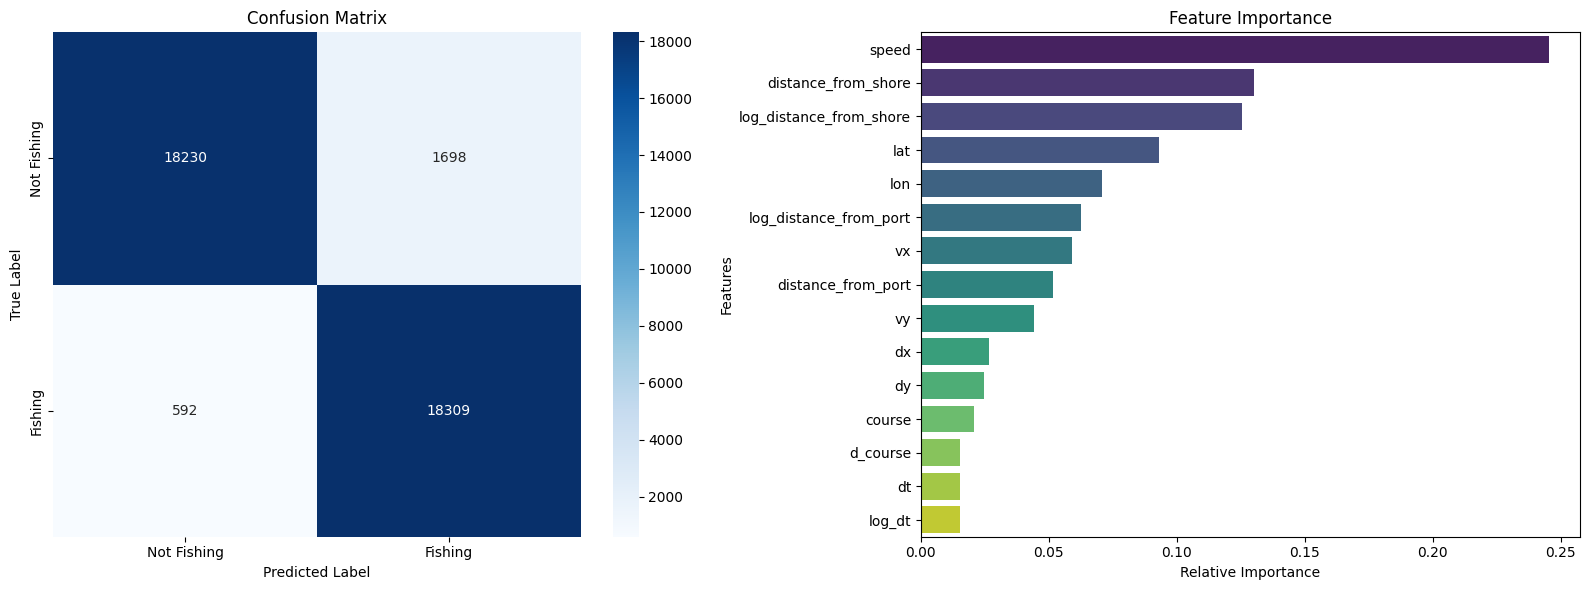

In [14]:
# 6. Informative Graphs
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Not Fishing', 'Fishing'], yticklabels=['Not Fishing', 'Fishing'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Plot Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
feature_ranking = pd.DataFrame({
    'Feature': X.columns[indices],
    'Importance': importances[indices]
})
sns.barplot(x='Importance', y='Feature', data=feature_ranking, ax=axes[1], palette='viridis')
axes[1].set_title('Feature Importance')
axes[1].set_xlabel('Relative Importance')
axes[1].set_ylabel('Features')

plt.tight_layout()
plt.show()


In [15]:
import os

# 1. Align the original dataframe features with what the model expects
# We must drop the same features dropped during training
X_full = df.drop(columns=features_to_drop, errors='ignore')

# Handle potential NaN values in the full dataset to ensure prediction doesn't fail
X_full = X_full.fillna(X_train.median())

# 2. Generate predictions (0 or 1) for all rows
all_predictions = rf_model.predict(X_full)

# 3. Create a standalone DataFrame for the predictions (do not modify or append to original df)
output_df = pd.DataFrame({'labels_is_fishing': all_predictions})

# 4. Define output path and save as parquet
save_directory = '/content/drive/MyDrive/Colab Notebooks/Colab Notebooks/Datasets'
os.makedirs(save_directory, exist_ok=True)
output_parquet_path = os.path.join(save_directory, 'Random_Forest_Trawler_labels.parquet')

output_df.to_parquet(output_parquet_path, index=False)
print(f"Successfully saved single column parquet as standalone to: {output_parquet_path}")
print(f"Shape of saved parquet: {output_df.shape}")

Successfully saved single column parquet as standalone to: /content/drive/MyDrive/Colab Notebooks/Colab Notebooks/Datasets/Random_Forest_Trawler_labels.parquet
Shape of saved parquet: (3175234, 1)
